# 03 - Modelling

Comparing Logistic Regression, Decision Tree, Random Forest and XGBoost.

- 80/20 split stratified on `loan_default` and grouped by customer (`random_state=42`)
- each model tuned with 5-fold CV on the train set (ROC-AUC)
- the test set is only used once at the end, on the chosen model

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

from train import models, X_train, y_train, X_test, y_test, groups, cv, find_threshold, scores
print(X_train.shape, X_test.shape, y_train.mean().round(3))

(2721, 32) (682, 32) 0.234


In [2]:
probs, best = {}, {}
for name, (pipe, params) in models.items():
    grid = GridSearchCV(pipe, params, scoring="roc_auc", cv=cv, n_jobs=-1)
    grid.fit(X_train, y_train, groups=groups)
    best[name] = grid.best_estimator_
    probs[name] = cross_val_predict(grid.best_estimator_, X_train, y_train, groups=groups,
                                    cv=cv, method="predict_proba")[:, 1]
    print(name, grid.best_params_)

logistic_regression {'model__C': 0.01}


decision_tree {'model__max_depth': 4, 'model__min_samples_leaf': 60}


random_forest {'model__max_depth': None, 'model__max_features': 0.3, 'model__min_samples_leaf': 20}


xgboost {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200}


## Class imbalance

Only ~23% of loans default, so at the usual 0.5 threshold the models hardly flag anyone:

In [3]:
pd.Series({name: (p >= 0.5)[y_train == 1].mean() for name, p in probs.items()}, name="recall at 0.5").round(3)

logistic_regression    0.126
decision_tree          0.160
random_forest          0.091
xgboost                0.138
Name: recall at 0.5, dtype: float64

Two ways to fix this: `class_weight="balanced"` or keep the model as is and lower the threshold.
Checking what class weights do to the probabilities:

In [4]:
lr_balanced = models["logistic_regression"][0].set_params(model__C=0.01, model__class_weight="balanced")
p_bal = cross_val_predict(lr_balanced, X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
models["logistic_regression"][0].set_params(model__class_weight=None)

print("actual default rate:      ", y_train.mean().round(3))
print("avg prob, no weights:     ", probs["logistic_regression"].mean().round(3))
print("avg prob, balanced weights:", p_bal.mean().round(3))
print("AUC no weights / balanced:", round(roc_auc_score(y_train, probs["logistic_regression"]), 3),
      round(roc_auc_score(y_train, p_bal), 3))

actual default rate:       0.234
avg prob, no weights:      0.233
avg prob, balanced weights: 0.453
AUC no weights / balanced: 0.739 0.74


Same AUC, but with class weights the probabilities are about double the real default rate.
Since the risk score is the probability x 100, I want the probabilities to be realistic,
so no class weights and the threshold is set to catch 70% of defaulters instead (no SMOTE needed).

## Model comparison (5-fold CV, threshold set for 70% recall)

In [5]:
results = {}
for name, p in probs.items():
    t = find_threshold(y_train, p)
    results[name] = {"threshold": t, **scores(y_train, p, t)}
results = pd.DataFrame(results).T.round(3)
results

,threshold,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.22,0.661,0.380,0.706,0.494,0.739
decision_tree,0.22,0.634,0.360,0.730,0.483,0.709
random_forest,0.24,0.664,0.382,0.705,0.496,0.727
xgboost,0.23,0.672,0.389,0.702,0.501,0.732


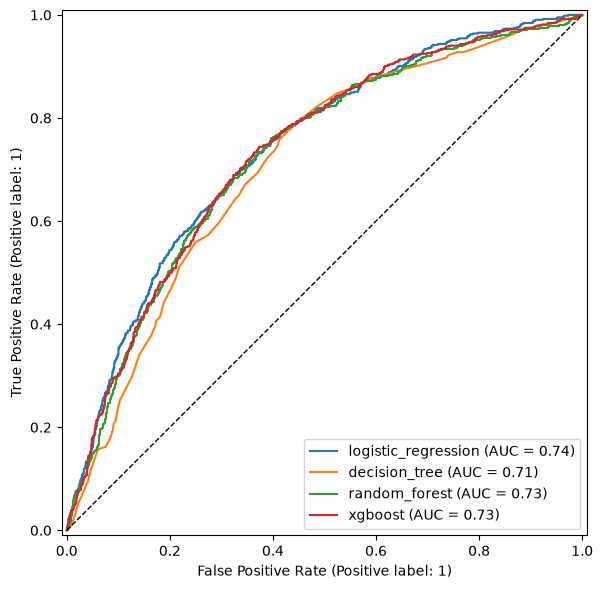

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_train, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
plt.tight_layout()

All four end up close. Logistic Regression has the best AUC (~0.74), XGBoost is right behind.
The tree models picked the most regularised settings (XGBoost depth 2, low learning rate), which
suggests the relationships are mostly simple / linear and there isn't much extra for them to find.

I also tried a wider XGBoost grid (depth 1-3, up to 1000 trees, min_child_weight) and dropping
the transaction features, nothing got past ~0.74.

## Outliers

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from features import num_cols, cat_cols

skewed = [c for c in num_cols if X_train[c].skew() > 2]
others = [c for c in num_cols if c not in skewed]
print(skewed)

prep = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), StandardScaler()), skewed),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), others),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
lr_log = Pipeline([("prep", prep), ("model", LogisticRegression(C=0.01, max_iter=2000))])
p = cross_val_predict(lr_log, X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
print("AUC with log:", round(roc_auc_score(y_train, p), 3), "vs", round(roc_auc_score(y_train, probs["logistic_regression"]), 3))

['annual_income', 'num_late_payments_90d', 'num_defaults_prior', 'bankruptcies', 'requested_amount', 'loan_term_months', 'loan_to_income', 'total_inflow', 'total_outflow', 'emi_outflow', 'avg_balance', 'inflow_outflow_ratio']


AUC with log: 0.74 vs 0.739


No real difference so the outliers are left as they are.

## Final model on the test set

logistic_regression threshold 0.22
ROC-AUC: 0.714
              precision    recall  f1-score   support

           0      0.858     0.636     0.730       522
           1      0.356     0.656     0.462       160

    accuracy                          0.641       682
   macro avg      0.607     0.646     0.596       682
weighted avg      0.740     0.641     0.667       682



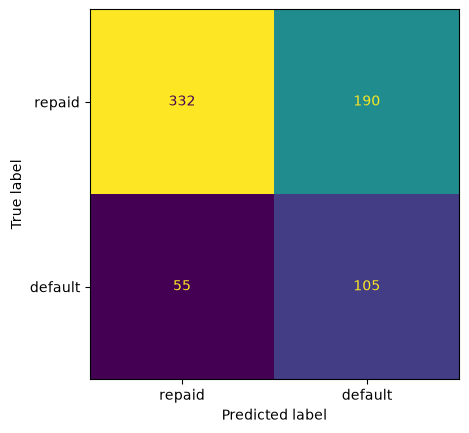

In [8]:
champion = results["roc_auc"].idxmax()
threshold = results.loc[champion, "threshold"]
model = best[champion]

test_prob = model.predict_proba(X_test)[:, 1]
print(champion, "threshold", threshold)
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 3))
print(classification_report(y_test, test_prob >= threshold, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, test_prob >= threshold, colorbar=False,
                                        display_labels=["repaid", "default"]);

Test AUC is 0.71 and recall is 0.66, a bit below the CV numbers and below the PRD targets
(AUC 0.80, recall 0.70). In business terms: out of 160 defaulters in the test set, 105 get flagged,
and about 1 in 3 flagged loans actually defaults.

## Feature importance

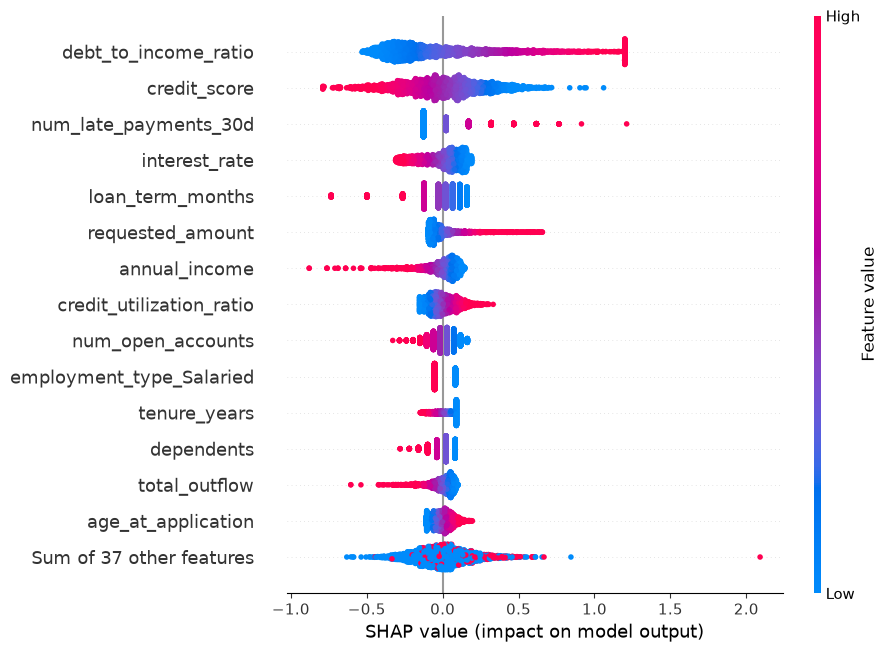

In [9]:
import shap

Xt = model["prep"].transform(X_train)
names = [n.split("__")[1] for n in model["prep"].get_feature_names_out()]
explainer = shap.Explainer(model["model"], shap.maskers.Independent(Xt, max_samples=len(Xt)))
sv = explainer(Xt)
sv.feature_names = names
shap.plots.beeswarm(sv, max_display=15)

In [10]:
importance = pd.DataFrame({
    "feature": names,
    "mean_abs_shap": np.abs(sv.values).mean(axis=0),
    "coefficient": model["model"].coef_[0],
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
importance.index += 1
importance.to_csv("../models/feature_importance.csv", index_label="rank")
importance.head(15).round(3)

,feature,mean_abs_shap,coefficient
1,debt_to_income_ratio,0.320,0.416
2,credit_score,0.214,-0.269
3,num_late_payments_30d,0.133,0.177
4,interest_rate,0.108,-0.131
5,loan_term_months,0.103,-0.148
6,requested_amount,0.081,0.125
7,annual_income,0.080,-0.113
8,credit_utilization_ratio,0.074,0.090
9,num_open_accounts,0.068,-0.084
10,employment_type_Salaried,0.065,-0.137


Checking that the tree models agree:

In [11]:
tree_imp = {}
for name in ["random_forest", "xgboost"]:
    m = best[name]
    tree_imp[name] = pd.Series(m["model"].feature_importances_,
                               index=[n.split("__")[1] for n in m["prep"].get_feature_names_out()])
tree_imp = pd.DataFrame(tree_imp)
tree_imp.rank(ascending=False).loc[importance["feature"].head(10)].astype(int)

,random_forest,xgboost
debt_to_income_ratio,1,1
credit_score,2,2
num_late_payments_30d,10,4
interest_rate,11,17
loan_term_months,14,14
requested_amount,7,20
annual_income,4,8
credit_utilization_ratio,8,18
num_open_accounts,20,25
employment_type_Salaried,23,13


## Notes

- Top drivers: debt-to-income ratio, credit score and 30-day late payments, then interest rate,
  loan term, requested amount and income. Lines up with the EDA and SQL query 7.10
  (score < 600 and DTI > 0.5 had the highest default rates).
- Higher interest rate and longer term come out as *lower* risk, which seems odd. I think it's
  really loan type showing through: Personal loans have the highest rates but default the least,
  Home loans have long terms and low rates but default the most.
- Random Forest and XGBoost agree on the top two (DTI and credit score), after that the order
  moves around quite a bit.
- Final model: Logistic Regression, no class weights, threshold 0.22. Saved by `src/train.py`
  to `models/default_model.pkl`.
- AUC stays around 0.74 whatever I try, so I think that's roughly the limit with these features.